In [2]:
import numpy as np 
import matplotlib.pyplot as plt 
from datetime import datetime
from data_loaders import DemandDataLoader 

In [3]:
def get_date(date):
    formats = [
        "%d-%b-%y",   # 01-Jan-23
        "%d-%b-%Y",   # 01-JAN-2010
        "%Y-%m-%d"    # 2025-01-01
    ]

    for fmt in formats:
        try:
            day = datetime.strptime(date, fmt).day 
            month = datetime.strptime(date, fmt).month
            return day, month
        except ValueError:
            continue

    raise ValueError(f"Unrecognised date format: {date}")


def compute_var(data):
    mean = sum(data) / len(data)
    squared_distance = 0 
    for x in data:
        squared_distance += (mean - x)**2
    return squared_distance / len(data) 
print(compute_var([4, 4, 4, 3]))

def get_daily_variances(year_data, column): #we will be specifically applying this to demand data, but this can be applied to any information from the data
    data = year_data[column].to_numpy()
    times = year_data["SETTLEMENT_DATE"]
    current_day, _ = get_date(times[0])
    daily_variances = []
    demand_during_day = []
    for x in range(len(times)):
        day, _ = get_date(times[x])
        if current_day == day:
            demand_during_day.append(data[x])
        else: 
            variance = compute_var(demand_during_day)
            daily_variances.append(variance)
            demand_during_day = []
            current_day = day
            demand_during_day.append(data[x])
    daily_variances.append(compute_var(demand_during_day))

    return daily_variances 



def get_daily_variances2(year_data, column):
    return year_data.groupby("SETTLEMENT_DATE")[column].var(ddof=0).tolist()

def convert_months_to_dates(length, start_year, start_month): #this doesn't include the day since I don't care 
    dates = []

    for x in range(length):
        year = x // 12  + start_year
        month = x % 12 + start_month
        dates.append(datetime(year, month, 1))
    return dates

def get_yearly_means(year_data, column):
    return year_data.groupby("SETTLEMENT_DATE")[column].mean().tolist()


0.1875


what do we want? Do we want the variance in the demand from each hour, so that we can see whether it has changed over time. we could also look into the variance as a fraction of the mean demand over a certain period. Maybe we should do it over the course of each year? or maybe each day? maybe the mean daily demand variance would be the most meaningful statistic, and we can see whether that has gone up over time 

In [4]:
directory = "D:/group project data/demand_data"
years = [x for x in range(2001, 2027)]
months = [x for x in range(1, 13)]

dataloader = DemandDataLoader(directory, years, "ND")
variances = dataloader.run_on_data(get_daily_variances2)

found 2001
2001 evaluated
found 2002
2002 evaluated
found 2003
2003 evaluated
found 2004
2004 evaluated
found 2005
2005 evaluated
found 2006
2006 evaluated
found 2007
2007 evaluated
found 2008
2008 evaluated
found 2009
2009 evaluated
found 2010
2010 evaluated
found 2011
2011 evaluated
found 2012
2012 evaluated
found 2013
2013 evaluated
found 2014
2014 evaluated
found 2015
2015 evaluated
found 2016
2016 evaluated
found 2017
2017 evaluated
found 2018
2018 evaluated
found 2019
2019 evaluated
found 2020
2020 evaluated
found 2021
2021 evaluated
found 2022
2022 evaluated
found 2023
2023 evaluated
found 2024
2024 evaluated
found 2025
2025 evaluated
found 2026
2026 evaluated


In [7]:
print(variances)

[[13874102.957899278, 40352344.40581596, 30247760.791232634, 29392371.164930552, 25449145.01692711, 12335055.67664928, 19218920.624999993, 37744024.00998259, 29647751.979166612, 29784195.11805558, 29816346.7078993, 23363664.206597235, 10532591.039930582, 15835311.831597202, 37386532.99826391, 29655480.722222243, 26211053.93359379, 26330404.020399287, 24147253.118055563, 11588244.718315981, 20055531.739149313, 40354166.07248257, 30894844.229166716, 24652041.164930537, 25527151.555555593, 23162657.76388889, 9704844.905815957, 15791308.305555567, 35198743.48914928, 28689676.60937503, 26300975.530815944, 28657107.451388896, 20974352.99305554, 9826898.164930543, 19821725.71831596, 36075933.19270829, 24789154.664930563, 22662991.12326392, 28037463.916232597, 17443429.759982653, 12477473.54123263, 15025012.895833336, 36534416.12326388, 20627945.373263877, 19613772.914930522, 21392714.401041698, 17455357.020833302, 7848307.95442709, 11860284.109375032, 29789754.472222213, 20100076.831597243, 2

Text(0.5, 1.0, 'mean daily national demand variance per year since 2000')

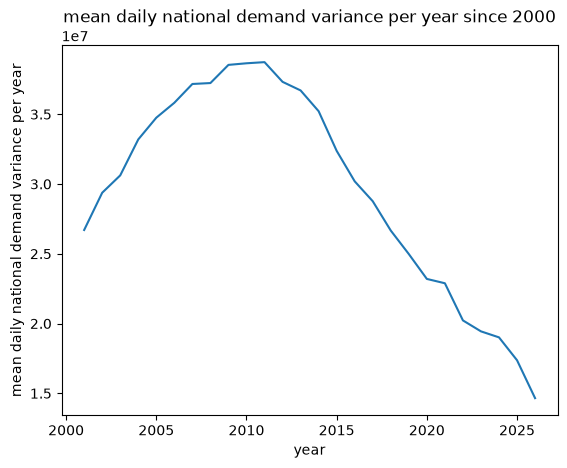

In [ ]:
import matplotlib.pyplot as plt 
mean_daily_variances = []
for x in variances:
    mean_daily_variances.append(sum(x) / len(x))
    
plt.plot([x+2001 for x in range(len(mean_daily_variances))], mean_daily_variances)
plt.xlabel("year")
plt.ylabel("mean daily national demand variance per year")
plt.title("mean daily national demand variance per year since 2000")

In [6]:
#next we want to look at the transmission system demand per year. That could also be quite interesting 
dataloader = DemandDataLoader(directory, years, "TSD")
daily_mean_TSD = dataloader.run_on_data(get_yearly_means)


found 2001
2001 evaluated
found 2002
2002 evaluated
found 2003
2003 evaluated
found 2004
2004 evaluated
found 2005
2005 evaluated
found 2006
2006 evaluated
found 2007
2007 evaluated
found 2008
2008 evaluated
found 2009
2009 evaluated
found 2010
2010 evaluated
found 2011
2011 evaluated
found 2012
2012 evaluated
found 2013
2013 evaluated
found 2014
2014 evaluated
found 2015
2015 evaluated
found 2016
2016 evaluated
found 2017
2017 evaluated
found 2018
2018 evaluated
found 2019
2019 evaluated
found 2020
2020 evaluated
found 2021
2021 evaluated
found 2022
2022 evaluated
found 2023
2023 evaluated
found 2024
2024 evaluated
found 2025
2025 evaluated
found 2026
2026 evaluated


In [7]:
daily_mean_TSD = daily_mean_TSD[5:]
yearly_mean_TSD = []
for x in daily_mean_TSD:
    yearly_mean_TSD.append(sum(x) / len(x))
    

Text(0.5, 1.0, 'mean yearly transmission system demand since 2000')

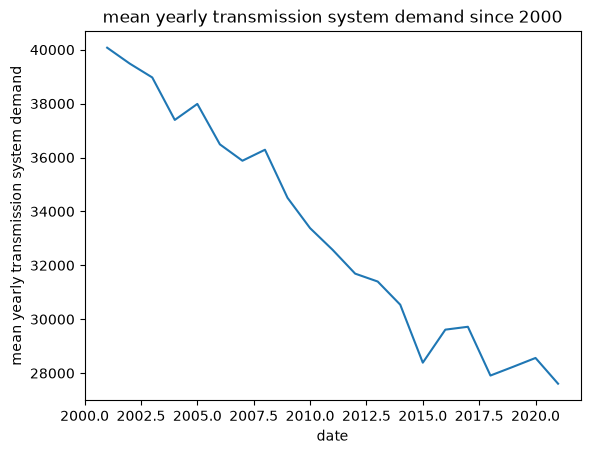

In [9]:
plt.plot([x+2001 for x in range(len(yearly_mean_TSD))], yearly_mean_TSD)
plt.xlabel("date")
plt.ylabel("mean yearly transmission system demand")
plt.title("mean yearly transmission system demand since 2000")

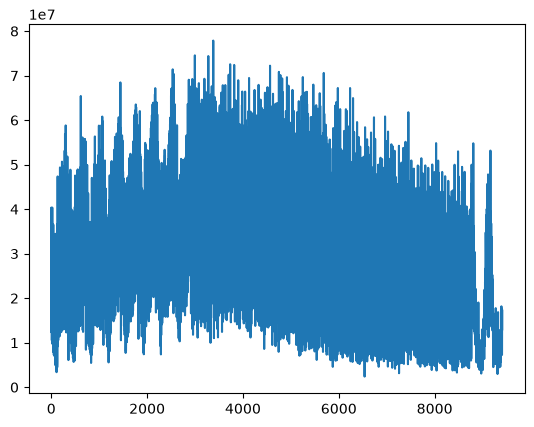

In [ ]:
all_daily_variances = []
for x in variances:
    for y in x:
        all_daily_variances.append(y)
plt.plot([x for x in range(len(all_daily_variances))], all_daily_variances)

In [24]:
print(variances)

[[13874102.957899278, 40352344.40581596, 30247760.791232634, 29392371.164930552, 25449145.01692711, 12335055.67664928, 19218920.624999993, 37744024.00998259, 29647751.979166612, 29784195.11805558, 29816346.7078993, 23363664.206597235, 10532591.039930582, 15835311.831597202, 37386532.99826391, 29655480.722222243, 26211053.93359379, 26330404.020399287, 24147253.118055563, 11588244.718315981, 20055531.739149313, 40354166.07248257, 30894844.229166716, 24652041.164930537, 25527151.555555593, 23162657.76388889, 9704844.905815957, 15791308.305555567, 35198743.48914928, 28689676.60937503, 26300975.530815944, 28657107.451388896, 20974352.99305554, 9826898.164930543, 19821725.71831596, 36075933.19270829, 24789154.664930563, 22662991.12326392, 28037463.916232597, 17443429.759982653, 12477473.54123263, 15025012.895833336, 36534416.12326388, 20627945.373263877, 19613772.914930522, 21392714.401041698, 17455357.020833302, 7848307.95442709, 11860284.109375032, 29789754.472222213, 20100076.831597243, 2

In [ ]:
print([len(x) for x in variances])

[365, 365, 365, 366, 365, 365, 365, 366, 365, 365, 365, 366, 365, 365, 365, 366, 365, 365, 365, 366, 365, 365, 365, 366, 365, 279]


In [36]:
def convert_months_to_dates(length, start_year, start_month): #this doesn't include the day since I don't care 
    dates = []

    for x in range(length):
        year = x // 12  + start_year
        month = x % 12 + start_month
        dates.append(datetime(year, month, 1))
    return dates



Text(0, 0.5, 'mean daily demand variance per month')

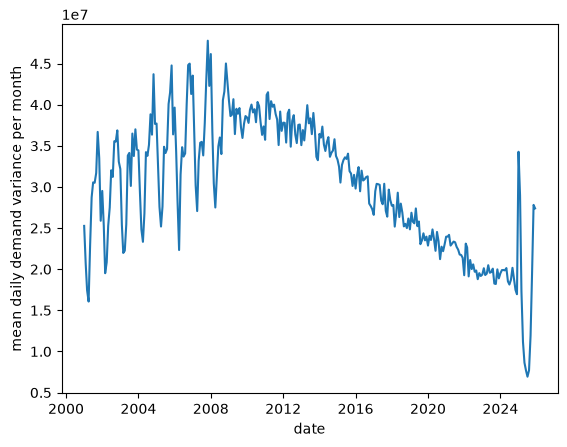

In [40]:
def get_mean_monthly_for_year(data, isLeap):
    months = [31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31]
    month_means = []
    if isLeap:
        months[1] += 1
    cumMonths = [0]
    for x in months:
        cumMonths.append(cumMonths[-1] + x)
    for x in range(len(cumMonths)-1):
        mean_for_month = data[cumMonths[x]:cumMonths[x+1]]
        month_means.append(sum(mean_for_month)/len(mean_for_month))
    return month_means


def data_mean_monthly(data, start_year):
    month_means = []
    isLeap = False
    for x in range(len(data)):
        if len(data[x]) not in [365, 366]:
               continue 
        if (start_year + x) % 4 == 0:
            isLeap = True 
        month_means_for_year = get_mean_monthly_for_year(data[x], isLeap) 
        for x in month_means_for_year:
            month_means.append(x)
        isLeap = False
    return month_means

monthly_means = data_mean_monthly(variances, 2001)

dates = convert_months_to_dates(len(monthly_means), 2001, 1)


plt.plot(dates, monthly_means)
plt.xlabel("date")
plt.ylabel("mean daily demand variance per month")

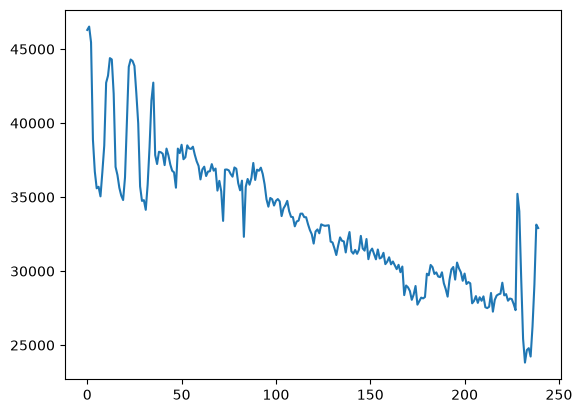

In [73]:
monthly_TSD_mean = data_mean_monthly(daily_mean_TSD, 2005)
plt.plot([x for x in range(len(monthly_TSD_mean))], monthly_TSD_mean)

In [77]:
#only 2009 data onwards talks about the amount of data being imported/exported via the different interconnects 
dataloader = DemandDataLoader(directory, [x for x in range(2009, 2025)], "EMBEDDED_WIND_GENERATION")
embedded_wind_generation_daily = dataloader.run_on_data(get_yearly_means)

found 2009
2009 evaluated
found 2010
2010 evaluated
found 2011
2011 evaluated
found 2012
2012 evaluated
found 2013
2013 evaluated
found 2014
2014 evaluated
found 2015
2015 evaluated
found 2016
2016 evaluated
found 2017
2017 evaluated
found 2018
2018 evaluated
found 2019
2019 evaluated
found 2020
2020 evaluated
found 2021
2021 evaluated
found 2022
2022 evaluated
found 2023
2023 evaluated
found 2024
2024 evaluated


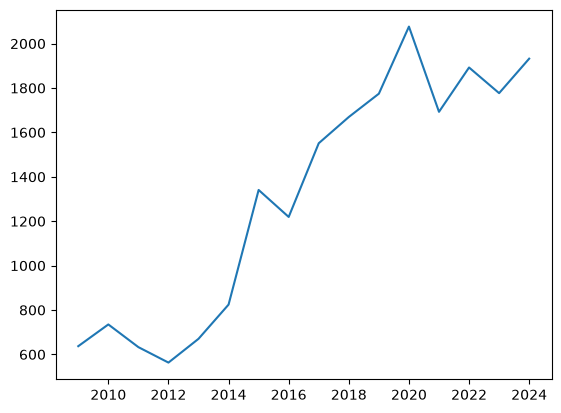

In [78]:
yearly_mean_embedded_wind_generation = []
for x in embedded_wind_generation_daily:
    yearly_mean_embedded_wind_generation.append(sum(x) / len(x))

plt.plot([x+2009 for x in range(len(yearly_mean_embedded_wind_generation))], yearly_mean_embedded_wind_generation)

found 2009
2009 evaluated
found 2010
2010 evaluated
found 2011
2011 evaluated
found 2012
2012 evaluated
found 2013
2013 evaluated
found 2014
2014 evaluated
found 2015
2015 evaluated
found 2016
2016 evaluated
found 2017
2017 evaluated
found 2018
2018 evaluated
found 2019
2019 evaluated
found 2020
2020 evaluated
found 2021
2021 evaluated
found 2022
2022 evaluated
found 2023
2023 evaluated
found 2024
2024 evaluated


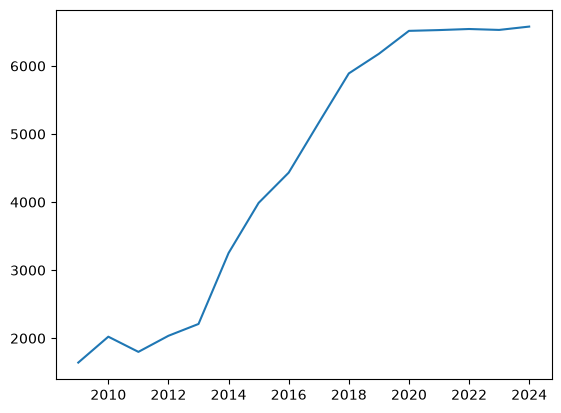

In [81]:
dataloader = DemandDataLoader(directory, [x for x in range(2009, 2025)], "EMBEDDED_WIND_CAPACITY")
embedded_wind_capacity_daily = dataloader.run_on_data(get_yearly_means)
embedded_wind_capacity_yearly_means = []
for x in embedded_wind_capacity_daily:
    embedded_wind_capacity_yearly_means.append(sum(x) / len(x))

plt.plot([x for x in range(2009, 2025)], embedded_wind_capacity_yearly_means)



found 2009
2009 evaluated
found 2010
2010 evaluated
found 2011
2011 evaluated
found 2012
2012 evaluated
found 2013
2013 evaluated
found 2014
2014 evaluated
found 2015
2015 evaluated
found 2016
2016 evaluated
found 2017
2017 evaluated
found 2018
2018 evaluated
found 2019
2019 evaluated
found 2020
2020 evaluated
found 2021
2021 evaluated
found 2022
2022 evaluated
found 2023
2023 evaluated
found 2024
2024 evaluated
found 2025
2025 evaluated


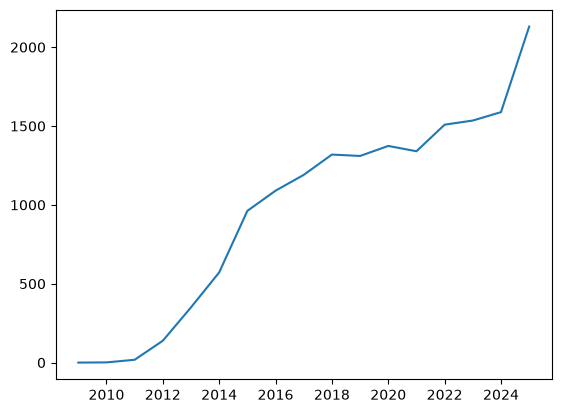

In [83]:
def get_yearly_means_for_column(column, start_year, end_year):
    dataloader = DemandDataLoader(directory, [x for x in range(start_year, end_year+1)], column)
    data = dataloader.run_on_data(get_yearly_means)
    yearly_means = []
    for x in data:
        yearly_means.append(sum(x) / len(x))
    return yearly_means 

yearly_mean_solar_generation = get_yearly_means_for_column("EMBEDDED_SOLAR_GENERATION", 2009, 2025)
plt.plot([x for x in range(2009, 2026)], yearly_mean_solar_generation)

found 2009
2009 evaluated
found 2010
2010 evaluated
found 2011
2011 evaluated
found 2012
2012 evaluated
found 2013
2013 evaluated
found 2014
2014 evaluated
found 2015
2015 evaluated
found 2016
2016 evaluated
found 2017
2017 evaluated
found 2018
2018 evaluated
found 2019
2019 evaluated
found 2020
2020 evaluated
found 2021
2021 evaluated
found 2022
2022 evaluated
found 2023
2023 evaluated
found 2024
2024 evaluated
found 2025
2025 evaluated


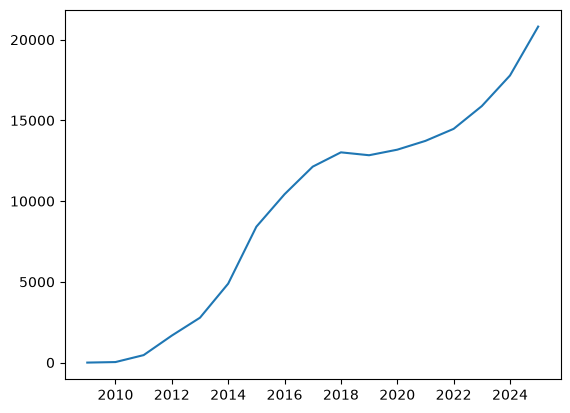

In [84]:
yearly_mean_solar_capacity = get_yearly_means_for_column("EMBEDDED_SOLAR_CAPACITY", 2009, 2025)
plt.plot([x for x in range(2009, 2026)], yearly_mean_solar_capacity)

In [89]:
dataloader = DemandDataLoader(directory, [x for x in range(2009, 2026)], "EMBEDDED_SOLAR_GENERATION")
solar_generation_variances = dataloader.run_on_data(get_daily_variances2)



found 2009
2009 evaluated
found 2010
2010 evaluated
found 2011
2011 evaluated
found 2012
2012 evaluated
found 2013
2013 evaluated
found 2014
2014 evaluated
found 2015
2015 evaluated
found 2016
2016 evaluated
found 2017
2017 evaluated
found 2018
2018 evaluated
found 2019
2019 evaluated
found 2020
2020 evaluated
found 2021
2021 evaluated
found 2022
2022 evaluated
found 2023
2023 evaluated
found 2024
2024 evaluated
found 2025
2025 evaluated


In [91]:
print(solar_generation_variances)

[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0

In [92]:
monthly_means_solar_output_var = data_mean_monthly(solar_generation_variances, 2009)

Text(0, 0.5, 'monthly mean embedded solar generation variance per day')

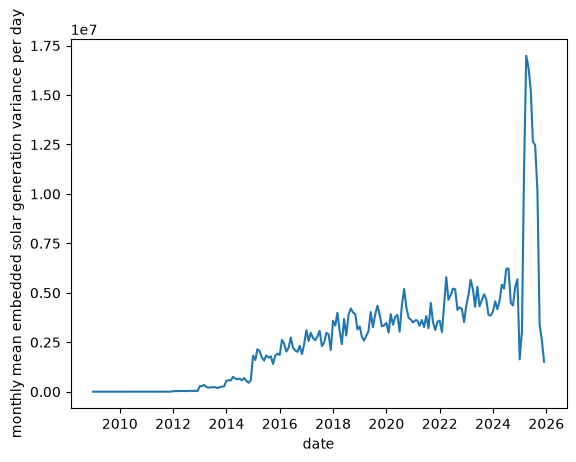

In [98]:
dates = convert_months_to_dates(len(monthly_means_solar_output_var), 2009, 1)

plt.plot(dates, monthly_means_solar_output_var)
plt.xlabel("date")
plt.ylabel("monthly mean embedded solar generation variance per day")


In [ ]:
dataloader = DemandDataLoader(directory, [x for x in range(2009, 2026)], "EMBEDDED_SOLAR_CAPACITY")
solar_capacity_means = dataloader.run_on_data(get_yearly_means)
dataloader2 = DemandDataLoader(directory, [x for x in range(2009, 2026)], "EMBEDDED_SOLAR_GENERATION")
solar_generation_means = dataloader2.run_on_data(get_yearly_means)




In [102]:
mean_daily_solar_generation_capacity_generation_ratio =  []
for x in range(len(solar_generation_means)):
    for y in range(len(solar_generation_means[x])):
        if solar_capacity_means[x][y] != 0.0:
            mean_daily_solar_generation_capacity_generation_ratio.append(solar_generation_means[x][y] / solar_capacity_means[x][y])

print(mean_daily_solar_generation_capacity_generation_ratio)


[0.00980392156862745, 0.05092592592592592, 0.0196256038647343, 0.049059139784946235, 0.01282051282051282, 0.015873015873015872, 0.03483606557377049, 0.013221153846153846, 0.09593023255813954, 0.0, 0.06531531531531531, 0.016606280193236712, 0.05510752688172043, 0.04487179487179487, 0.010912698412698412, 0.025873655913978496, 0.05488782051282051, 0.09043560606060606, 0.0, 0.061936936936936936, 0.02355072463768116, 0.06575520833333333, 0.05128205128205128, 0.019841269841269844, 0.024865591397849465, 0.02283653846153846, 0.08001893939393939, 0.006944444444444444, 0.051238738738738736, 0.012202380952380952, 0.056640625, 0.046296296296296294, 0.019841269841269844, 0.019153225806451613, 0.0589622641509434, 0.06770833333333333, 0.0, 0.06813063063063063, 0.02261904761904762, 0.068359375, 0.037808641975308636, 0.016098484848484848, 0.014112903225806451, 0.039308176100628936, 0.05113636363636364, 0.003472222222222222, 0.04111842105263158, 0.02291666666666667, 0.060546875, 0.02700617283950617, 0.0

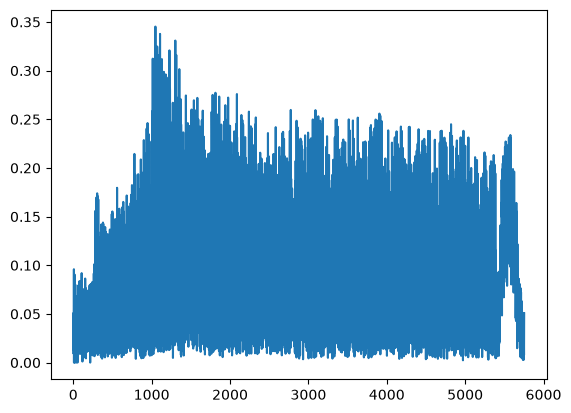

In [103]:
plt.plot([x for x in range(len(mean_daily_solar_generation_capacity_generation_ratio))], mean_daily_solar_generation_capacity_generation_ratio)

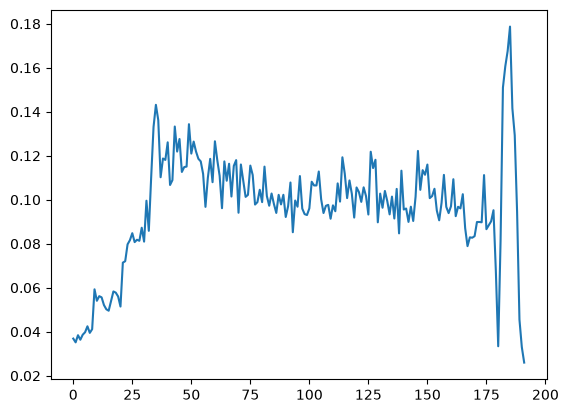

In [105]:
means_per_30_days = []
items_during_30_period = []
for x in range(len(mean_daily_solar_generation_capacity_generation_ratio)):
    items_during_30_period.append(mean_daily_solar_generation_capacity_generation_ratio[x])
    if x % 30 == 0 and x != 0:
        means_per_30_days.append(sum(items_during_30_period) / len(items_during_30_period))
        items_during_30_period = []
means_per_30_days.append(sum(items_during_30_period) / len(items_during_30_period))

    
plt.plot([x for x in range(len(means_per_30_days))], means_per_30_days)



found 2009
2009 evaluated
found 2010
2010 evaluated
found 2011
2011 evaluated
found 2012
2012 evaluated
found 2013
2013 evaluated
found 2014
2014 evaluated
found 2015
2015 evaluated
found 2016
2016 evaluated
found 2017
2017 evaluated
found 2018
2018 evaluated
found 2019
2019 evaluated
found 2020
2020 evaluated
found 2021
2021 evaluated
found 2022
2022 evaluated
found 2023
2023 evaluated
found 2024
2024 evaluated
found 2025
2025 evaluated
found 2009
2009 evaluated
found 2010
2010 evaluated
found 2011
2011 evaluated
found 2012
2012 evaluated
found 2013
2013 evaluated
found 2014
2014 evaluated
found 2015
2015 evaluated
found 2016
2016 evaluated
found 2017
2017 evaluated
found 2018
2018 evaluated
found 2019
2019 evaluated
found 2020
2020 evaluated
found 2021
2021 evaluated
found 2022
2022 evaluated
found 2023
2023 evaluated
found 2024
2024 evaluated
found 2025
2025 evaluated
found 2009
2009 evaluated
found 2010
2010 evaluated
found 2011
2011 evaluated
found 2012
2012 evaluated
found 2013
2

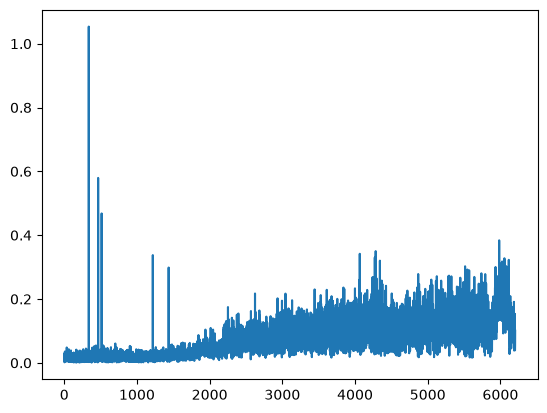

In [107]:
wind_dataloader= DemandDataLoader(directory, [x for x in range(2009, 2026)], "EMBEDDED_WIND_GENERATION")
solar_dataloader = DemandDataLoader(directory, [x for x in range(2009, 2026)], "EMBEDDED_SOLAR_GENERATION")
TSD_dataloader = DemandDataLoader(directory, [x for x in range(2009, 2026)], "TSD")
embedded_wind_generation_daily = wind_dataloader.run_on_data(get_yearly_means)
embedded_solar_generation_daily = solar_dataloader.run_on_data(get_yearly_means)
tsd_daily = TSD_dataloader.run_on_data(get_yearly_means)


embedded_renewables_TSD_fraction = []
for x in range(len(tsd_daily)):
    for y in range(len(tsd_daily[x])):
        if tsd_daily[x][y] != 0:
            embedded_renewables_TSD_fraction.append((embedded_wind_generation_daily[x][y] + embedded_solar_generation_daily[x][y])/tsd_daily[x][y])

plt.plot([x for x in range(len(embedded_renewables_TSD_fraction))], embedded_renewables_TSD_fraction)


In [109]:
non_BM_dataloader = DemandDataLoader(directory, [x for x in range(2009, 2026)], "NON_BM_STOR")
non_BM_means = non_BM_dataloader.run_on_data(get_yearly_means)


found 2009
2009 evaluated
found 2010
2010 evaluated
found 2011
2011 evaluated
found 2012
2012 evaluated
found 2013
2013 evaluated
found 2014
2014 evaluated
found 2015
2015 evaluated
found 2016
2016 evaluated
found 2017
2017 evaluated
found 2018
2018 evaluated
found 2019
2019 evaluated
found 2020
2020 evaluated
found 2021
2021 evaluated
found 2022
2022 evaluated
found 2023
2023 evaluated
found 2024
2024 evaluated
found 2025
2025 evaluated


In [111]:
monthly_nonBM_means = data_mean_monthly(non_BM_means, 2009)

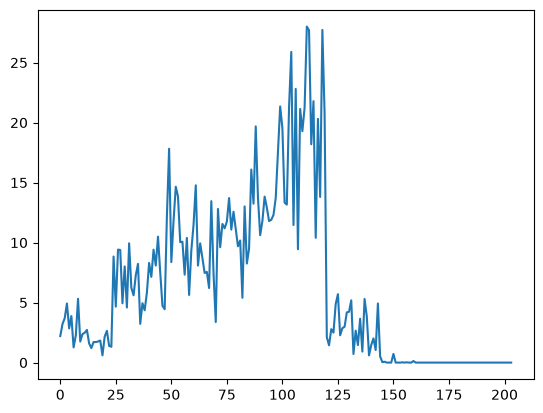

In [112]:
plt.plot([x for x in range(len(monthly_nonBM_means))], monthly_nonBM_means)

In [10]:
dataloader = DemandDataLoader(directory, years, "TSD")
daily_mean_TSD = dataloader.run_on_data(get_yearly_means)
daily_variance_TSD = dataloader.run_on_data(get_daily_variances)

found 2001
2001 evaluated
found 2002
2002 evaluated
found 2003
2003 evaluated
found 2004
2004 evaluated
found 2005
2005 evaluated
found 2006
2006 evaluated
found 2007
2007 evaluated
found 2008
2008 evaluated
found 2009
2009 evaluated
found 2010
2010 evaluated
found 2011
2011 evaluated
found 2012
2012 evaluated
found 2013
2013 evaluated
found 2014
2014 evaluated
found 2015
2015 evaluated
found 2016
2016 evaluated
found 2017
2017 evaluated
found 2018
2018 evaluated
found 2019
2019 evaluated
found 2020
2020 evaluated
found 2021
2021 evaluated
found 2022
2022 evaluated
found 2023
2023 evaluated
found 2024
2024 evaluated
found 2025
2025 evaluated
found 2026
2026 evaluated
found 2001
2001 evaluated
found 2002
2002 evaluated
found 2003
2003 evaluated
found 2004
2004 evaluated
found 2005
2005 evaluated
found 2006
2006 evaluated
found 2007
2007 evaluated
found 2008
2008 evaluated
found 2009
2009 evaluated
found 2010
2010 evaluated
found 2011
2011 evaluated
found 2012
2012 evaluated
found 2013
2

In [ ]:
print(daily_mean_TSD)
print(daily_variance_TSD)


[[nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan

In [19]:
print(daily_mean_TSD[5:]) #it appears it is necessary to cut off the first 4
daily_mean_TSD = daily_mean_TSD[5:]
daily_variance_TSD = daily_variance_TSD[5:]


[[38241.1875, 40219.5, 46050.645833333336, 48208.75, 49330.708333333336, 49266.5, 44535.541666666664, 43636.708333333336, 48685.0, 48823.520833333336, 48166.1875, 49022.208333333336, 47516.854166666664, 42444.708333333336, 41326.895833333336, 47398.791666666664, 47832.416666666664, 47323.083333333336, 46184.520833333336, 45250.9375, 41582.0, 41478.791666666664, 48717.604166666664, 49535.75, 49582.625, 49291.75, 49825.0, 44087.354166666664, 42942.791666666664, 48919.625, 49634.625, 50599.9375, 51180.395833333336, 50107.583333333336, 44317.520833333336, 42173.6875, 47775.291666666664, 47986.770833333336, 47556.145833333336, 48539.416666666664, 48788.416666666664, 43263.520833333336, 41587.4375, 46798.166666666664, 47190.75, 46101.75, 46381.541666666664, 45750.041666666664, 41529.875, 41273.458333333336, 47118.770833333336, 48328.416666666664, 49213.1875, 49592.541666666664, 48225.6875, 43003.791666666664, 42039.729166666664, 47917.625, 48193.916666666664, 49606.541666666664, 49686.395833

In [23]:
monthly_mean_TSD = []
monthly_variance_TSD = []
for x in daily_mean_TSD:
    monthly_mean_TSD.append(sum(x) / len(x))
for x in daily_variance_TSD:
    monthly_variance_TSD.append(sum(x) / len(x))

variance_over_mean_TSD = []
for x in range(len(monthly_mean_TSD)):
    variance_over_mean_TSD.append(monthly_variance_TSD[x] / monthly_mean_TSD[x])

print(variance_over_mean_TSD)

[np.float64(763.4225019366505), np.float64(792.1705710194616), np.float64(778.2331909385427), np.float64(885.8167480802077), np.float64(889.9224153005116), np.float64(925.7355616319819), np.float64(875.6872679368001), np.float64(880.0608106478116), np.float64(906.573862949507), np.float64(862.9927583827796), np.float64(771.0870333424149), np.float64(799.2196821721832), np.float64(753.5635635157334), np.float64(743.0147705503767), np.float64(724.0453070804049), np.float64(677.981683682321), np.float64(499.6795271242476), np.float64(558.6994965713739), np.float64(575.024443632959), np.float64(546.0486456625204), np.float64(512.5714635055803)]


Text(0.5, 1.0, 'mean daily variance TSD divided by mean TSD since 2006')

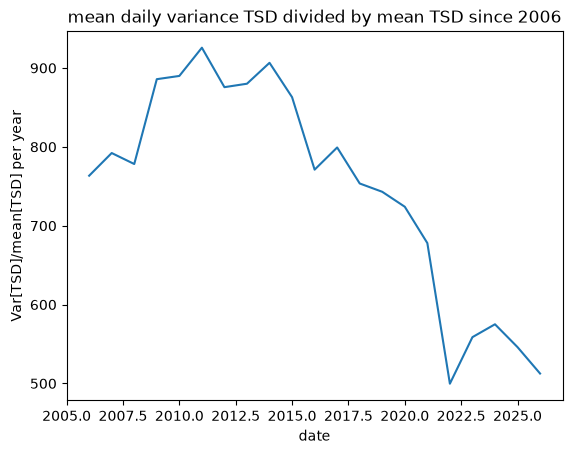

In [26]:
plt.plot([x+2006 for x in range(len(variance_over_mean_TSD))], variance_over_mean_TSD)
plt.xlabel("date")
plt.ylabel("Var[TSD]/mean[TSD] per year")
plt.title("mean daily variance TSD divided by mean TSD since 2006")